# 134 · MuJoCo as a perfect world model: MPPI planning with `mujoco.rollout`

In [1]:
import time, numpy as np, mujoco, matplotlib.pyplot as plt
from mujoco import rollout
from vlacourse.rl_envs import PENDULUM_XML
from vlacourse import show_video

SUB = 5

def pendulum(mass=1.0, length=1.0):
    m = mujoco.MjModel.from_xml_string(PENDULUM_XML.format(m=mass, L=length, g=-9.81, tmax=2.0))
    return m, mujoco.MjData(m)

def cost_from_states(states, ctrl):
    th = (states[..., 1] + np.pi) % (2 * np.pi) - np.pi; w = states[..., 2]
    return (th ** 2 + 0.1 * w ** 2).reshape(len(states), -1, SUB).mean(-1).sum(-1) + 0.001 * (ctrl[..., 0] ** 2).reshape(len(ctrl), -1, SUB).mean(-1).sum(-1)

class MPPI:
    def __init__(self, model, horizon=30, samples=256, sigma=1.0, lam=1.0, seed=0):
        self.m, self.H, self.K, self.sigma, self.lam = model, horizon, samples, sigma, lam
        self.datas = [mujoco.MjData(model) for _ in range(8)]
        self.U, self.rng = np.zeros(horizon), np.random.default_rng(seed)
        self.spec = mujoco.mjtState.mjSTATE_FULLPHYSICS

    def plan(self, data):
        x0 = np.zeros(mujoco.mj_stateSize(self.m, self.spec)); mujoco.mj_getState(self.m, data, x0, self.spec)
        eps = self.rng.normal(0, self.sigma, (self.K, self.H))
        U = np.clip(self.U[None] + eps, -2, 2)
        ctrl = np.repeat(U, SUB, axis=1)[..., None]
        states, _ = rollout.rollout(self.m, self.datas, np.repeat(x0[None], self.K, 0), ctrl)
        c = cost_from_states(states, ctrl)
        w = np.exp(-(c - c.min()) / self.lam); w /= w.sum()
        self.U = (w[:, None] * U).sum(0)
        u0 = self.U[0]
        self.U = np.r_[self.U[1:], self.U[-1]]
        return u0, c.min()

def run(planner, real_model, steps=200, render=False):
    d = mujoco.MjData(real_model); d.qpos[0] = np.pi; mujoco.mj_forward(real_model, d)
    total, frames, r = 0.0, [], mujoco.Renderer(real_model, 200, 200) if render else None
    for t in range(steps):
        u, _ = planner.plan(d)
        d.ctrl[0] = u; mujoco.mj_step(real_model, d, SUB)
        th = (d.qpos[0] + np.pi) % (2 * np.pi) - np.pi
        total -= th ** 2 + 0.1 * d.qvel[0] ** 2 + 0.001 * u ** 2
        if render and t % 2 == 0:
            cam = mujoco.MjvCamera(); cam.lookat[:] = [0, 0, 1.5]; cam.distance, cam.azimuth, cam.elevation = 4, 90, 0
            r.update_scene(d, cam); frames.append(r.render())
    return total, frames

MPPI with the exact MuJoCo model: return -366  (2s for 200 control steps, 256 rollouts x 30 steps each)
compare: SAC after 20k environment steps reached about -215 (S05 notebook 50) -- the planner needs NO training, only a model


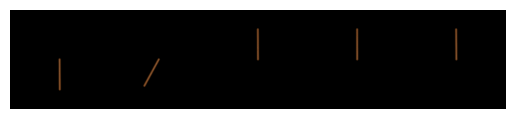

In [2]:
m, _ = pendulum()
t0 = time.time()
ret, frames = run(MPPI(m), m, render=True)
print(f"MPPI with the exact MuJoCo model: return {ret:.0f}  ({time.time() - t0:.0f}s for 200 control steps, 256 rollouts x 30 steps each)")
print("compare: SAC after 20k environment steps reached about -215 (S05 notebook 50) -- the planner needs NO training, only a model")
show_video(frames, fps=25, title="MPPI swing-up")
plt.imshow(np.hstack(frames[::20][:6])); plt.axis("off"); plt.show()

true mass 0.5: plan with exact model    -188 | plan with nominal (wrong) model    -212


true mass 0.8: plan with exact model    -354 | plan with nominal (wrong) model    -360


true mass 1.0: plan with exact model    -366 | plan with nominal (wrong) model    -366


true mass 1.25: plan with exact model    -501 | plan with nominal (wrong) model    -498


true mass 1.6: plan with exact model    -632 | plan with nominal (wrong) model    -635


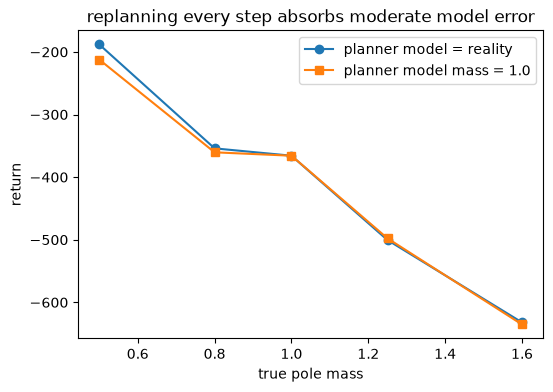

In [3]:
rows = []
for mass in [0.5, 0.8, 1.0, 1.25, 1.6]:
    m_true, _ = pendulum(mass=mass)
    ret_exact, _ = run(MPPI(m_true), m_true)
    ret_wrong, _ = run(MPPI(pendulum(mass=1.0)[0]), m_true)
    rows.append((mass, ret_exact, ret_wrong)); print(f"true mass {mass}: plan with exact model {ret_exact:7.0f} | plan with nominal (wrong) model {ret_wrong:7.0f}")
rows = np.array(rows)
plt.figure(figsize=(6, 4)); plt.plot(rows[:, 0], rows[:, 1], "o-", label="planner model = reality"); plt.plot(rows[:, 0], rows[:, 2], "s-", label="planner model mass = 1.0")
plt.xlabel("true pole mass"); plt.ylabel("return"); plt.legend(); plt.title("replanning every step absorbs moderate model error"); plt.show()

In [4]:
for K in [16, 64, 256]:
    for H in [10, 30]:
        t0 = time.time(); ret, _ = run(MPPI(m, horizon=H, samples=K), m, steps=150)
        print(f"samples {K:3d} horizon {H:2d}: return {ret:7.0f}   {(time.time() - t0) / 150 * 1000:5.1f} ms per control step")

samples  16 horizon 10: return    -939     0.4 ms per control step


samples  16 horizon 30: return    -438     0.7 ms per control step


samples  64 horizon 10: return    -902     0.8 ms per control step


samples  64 horizon 30: return    -368     1.9 ms per control step


samples 256 horizon 10: return    -904     2.4 ms per control step


samples 256 horizon 30: return    -366     6.7 ms per control step
